In [1]:
import json
import platform
from importlib.metadata import version
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from atividades.figuras_modelos import confusoes, desempenho, painel_roc
from atividades.modelos_supervisionados import (
    ALVO, ID, MESES, REFERENCIA, SEMENTE, ajustar_final, classificar, conferir_dobra,
    diagnosticos, escolher, ler_base, validar,
)
from atividades.representacoes import ENTRADAS

dados = Path("datasets/preparados_02")
saida = Path("resultados/atividade_03")
figuras = Path("figuras/atividade_03")
for pasta in (saida, figuras):
    pasta.mkdir(parents=True, exist_ok=True)

manifesto = json.loads((dados / "manifesto.json").read_text(encoding="utf-8"))
assert (manifesto["alvo"], manifesto["id"], manifesto["entradas"]) == (ALVO, ID, ENTRADAS)
versoes = {p: version(p) for p in ("numpy", "pandas", "scipy", "scikit-learn", "pyarrow",
                                   "matplotlib", "joblib", "threadpoolctl")}
dev = ler_base(dados, "desenvolvimento")
particoes = pd.read_parquet(dados / "particoes.parquet")
datas = pd.read_parquet(dados / "auditoria.parquet", columns=[ID, "ocorrencia", "emissao"]).set_index(ID, verify_integrity=True)
assert len(dev) == 5988
dobras = {mes: conferir_dobra(dev, dev, datas, particoes, mes) for mes in MESES}
display(pd.DataFrame([{"mês": m, "treino": len(t), "validação": len(v),
                       "classes no treino": t[ALVO].nunique(), "classes na validação": v[ALVO].nunique()}
                      for m, (t, v) in dobras.items()]))
display(dev[ALVO].value_counts(dropna=False).rename("registros no desenvolvimento").to_frame())

C:\Users\ARISTT~1\AppData\Local\Temp\ipykernel_88072\1487433694.py:31: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  datas = pd.read_parquet(dados / "auditoria.parquet", columns=[ID, "ocorrencia", "emissao"]).set_index(ID, verify_integrity=True)


,mês,treino,validação,classes no treino,classes na validação
0,3,1816,1264,39,38
1,4,3004,1202,39,41
2,5,4203,1305,41,40


,registros no desenvolvimento
parte_atingida_classe,
dedo,1166
pe (exceto artelhos),537
mao (exceto punho ou,369
joelho,330
partes multiplas - a,326
articulacao do torno,293
sistema nervoso,248
perna (entre o torno,231
braco (entre o punho,231


,familia,representacao,variante,campos,f1_medio,desvio_f1,acuracia_media,precisao_media,recall_medio
0,MLP,"Tipo, agente e divisão",12,3,0.103624,0.002836,0.261626,0.110109,0.111113
4,Random Forest,"Tipo, agente e divisão",10,3,0.092885,0.005127,0.254885,0.099666,0.100071
6,Árvore,"Tipo, agente e divisão",6,3,0.092625,0.005382,0.243598,0.097993,0.100776
12,KNN,"Tipo, agente e divisão",3,3,0.086514,0.010330,0.250314,0.098869,0.095869
112,Classe mais frequente,Classe mais frequente,-1,0,0.008139,0.000345,0.192908,0.004857,0.025235


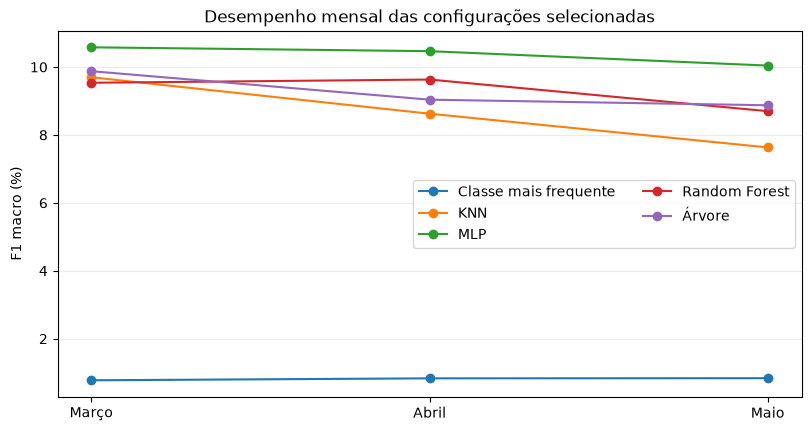

In [2]:
mensais, por_classe, escores = validar(dobras)
assert len(mensais) == (7 * 4 * 4 + 1) * len(MESES)
mensais.to_parquet(saida / "validacao_mensal.parquet", index=False)
por_classe.to_parquet(saida / "validacao_por_classe.parquet", index=False)
ranking = classificar(mensais)
ranking.to_parquet(saida / "comparacao.parquet", index=False)
candidatos = ranking.loc[ranking.familia.ne(REFERENCIA)]
vencedor = escolher(candidatos)
finalistas = pd.DataFrame([escolher(grupo) for _, grupo in ranking.groupby("familia")])
display(finalistas.sort_values("f1_medio", ascending=False))
fig_validacao = desempenho(mensais, finalistas)
fig_validacao.savefig(figuras / "validacao_mensal.png", dpi=135)
plt.show()

In [3]:
com_agente, sem_agente = "Tipo, agente e divisão", "Sem agente"
pares = mensais.loc[mensais.representacao.eq(com_agente)].merge(
    mensais.loc[mensais.representacao.eq(sem_agente)], on=["familia", "variante", "mes"],
    suffixes=("_com", "_sem"), validate="one_to_one")
assert pares.n_com.eq(pares.n_sem).all()
pares["diferenca_f1"] = pares.f1_macro_com - pares.f1_macro_sem
pares.to_parquet(saida / "comparacao_agente.parquet", index=False)
display(pares.groupby("familia")[["f1_macro_com", "f1_macro_sem", "diferenca_f1"]].mean())
display(mensais.groupby("familia").agg(ajustes=("mes", "size"),
        avisos=("aviso", lambda s: s.ne("").sum()), max_iteracoes=("iteracoes", "max")))

,f1_macro_com,f1_macro_sem,diferenca_f1
familia,,,
KNN,0.074916,0.051144,0.023772
MLP,0.096921,0.050896,0.046024
Random Forest,0.064344,0.043365,0.020979
Árvore,0.078860,0.045241,0.033619


,ajustes,avisos,max_iteracoes
familia,,,
Classe mais frequente,3,0,NaN
KNN,84,0,NaN
MLP,84,79,300.0
Random Forest,84,0,NaN
Árvore,84,0,NaN


In [4]:
matrizes, tabelas_auc, pontos_roc, diagnostico_mensal = [], [], [], []
def registrar_diagnostico(mes, familia, y, classes, prob):
    resumo, detalhe, matriz, aucs, curvas = diagnosticos(y, classes, prob)
    chave = dict(mes=mes, familia=familia)
    contagens = matriz.rename_axis("registrada").rename_axis("prevista", axis=1)
    longa = contagens.stack().rename("contagem").reset_index()
    longa["proporcao_linha"] = longa.contagem / longa.groupby("registrada").contagem.transform("sum").replace(0, np.nan)
    matrizes.append(longa.assign(**chave))
    tabelas_auc.append(aucs.assign(**chave))
    pontos_roc.append(curvas.assign(**chave))
    diagnostico_mensal.append(dict(**chave, **resumo))
    return detalhe

for linha in finalistas.itertuples():
    for mes, (_, valida) in dobras.items():
        classes, prob = escores[mes, linha.representacao, linha.variante]
        registrar_diagnostico(mes, linha.familia, valida[ALVO], classes, prob)
del escores
display(pd.DataFrame(diagnostico_mensal)[["mes", "familia", "auc_macro", "classes_com_auc"]])

,mes,familia,auc_macro,classes_com_auc
0,3,Classe mais frequente,0.500000,38
1,4,Classe mais frequente,0.500000,39
2,5,Classe mais frequente,0.500000,39
3,3,KNN,0.580820,38
4,4,KNN,0.584938,39
5,5,KNN,0.565736,39
6,3,MLP,0.643192,38
7,4,MLP,0.641404,39
8,5,MLP,0.663714,39
9,3,Random Forest,0.618000,38


In [5]:
ids_finais = particoes.loc[particoes.mes.eq(6) & particoes.papel.eq("treino"), ID]
treino_final = dev.loc[ids_finais]
datas_dev = datas.loc[dev.index]
elegivel = (datas_dev.ocorrencia.lt("2026-06-01") & datas_dev.emissao.ge(datas_dev.ocorrencia)
            & datas_dev.emissao.lt("2026-06-01") & dev[ALVO].notna())
assert set(treino_final.index) == set(dev.index[elegivel]) and len(treino_final) == 5565
modelo, aviso_final = ajustar_final(vencedor, treino_final)
campos = ENTRADAS[vencedor.representacao]
escolha = dict(familia=vencedor.familia, representacao=vencedor.representacao, entradas=campos,
               variante=int(vencedor.variante), parametros=modelo[-1].get_params(),
               f1_validacao=float(vencedor.f1_medio), semente=SEMENTE,
               iteracoes=getattr(modelo[-1], "n_iter_", None), aviso=aviso_final,
               treino=len(treino_final), python=platform.python_version(), versoes=versoes)
(saida / "escolha.json").write_text(json.dumps(escolha, ensure_ascii=False, indent=2), encoding="utf-8")
arquivo_modelo = saida / "vencedor.joblib"
joblib.dump(modelo, arquivo_modelo, compress=3)
amostra = dev[campos].sample(64, random_state=SEMENTE)
recarregado = joblib.load(arquivo_modelo)
np.testing.assert_array_equal(modelo.predict(amostra), recarregado.predict(amostra))
np.testing.assert_array_equal(modelo.predict_proba(amostra), recarregado.predict_proba(amostra))
display(vencedor.to_frame("configuração escolhida"))

,configuração escolhida
familia,MLP
representacao,"Tipo, agente e divisão"
variante,12
campos,3
f1_medio,0.103624
desvio_f1,0.002836
acuracia_media,0.261626
precisao_media,0.110109
recall_medio,0.111113


In [6]:
junho = ler_base(dados, "teste_junho")
assert len(junho) == 1213 and dev.index.intersection(junho.index).empty
_, teste = conferir_dobra(dev, junho, datas, particoes, 6)
prob_junho = recarregado.predict_proba(teste[campos])
classes_junho = recarregado.classes_
detalhe_junho = registrar_diagnostico(6, vencedor.familia, teste[ALVO], classes_junho, prob_junho)
detalhe_junho.to_parquet(saida / "junho_por_classe.parquet", index=False)
populacao = pd.concat({nome: base[ALVO].value_counts(dropna=False) for nome, base in
                      [("desenvolvimento", dev), ("treino_final", treino_final), ("junho", junho)]},
                     axis=1).fillna(0).astype(int).rename_axis("classe")
populacao.to_parquet(saida / "populacao.parquet")
for nome, partes in [("matrizes_confusao", matrizes), ("auc_por_classe", tabelas_auc), ("curvas_roc", pontos_roc)]:
    pd.concat(partes, ignore_index=True).to_parquet(saida / f"{nome}.parquet", index=False)
diagnostico_mensal = pd.DataFrame(diagnostico_mensal)
diagnostico_mensal.to_parquet(saida / "diagnostico_mensal.parquet", index=False)
display(diagnostico_mensal.tail(1))
display(detalhe_junho.sort_values("suporte", ascending=False))
display(pd.DataFrame([{"alvos ausentes no desenvolvimento": dev[ALVO].isna().sum(),
                       "alvos ausentes em junho": junho[ALVO].isna().sum(),
                       "emissões de junho após 30/06": datas.loc[teste.index].emissao.gt("2026-06-30").sum()}]))

,mes,familia,n,classes_presentes,acuracia,precisao_macro,recall_macro,f1_macro,sem_previsao,registros_inéditos,auc_macro,classes_com_auc
15,6,MLP,1213,38,0.256389,0.084687,0.096715,0.0825,2,0,0.654602,38


,classe,suporte,previsoes,vp,fp,fn,vn,precisao,recall,f1,precisao_indefinida,inédita
15,dedo,229,373,163,210,66,774,0.436997,0.711790,0.541528,False,False
29,pe (exceto artelhos),93,187,33,154,60,966,0.176471,0.354839,0.235714,False,False
21,mao (exceto punho ou,79,58,12,46,67,1088,0.206897,0.151899,0.175182,False,False
18,joelho,75,77,14,63,61,1075,0.181818,0.186667,0.184211,False,False
28,partes multiplas - a,69,118,22,96,47,1048,0.186441,0.318841,0.235294,False,False
36,sistema nervoso,56,64,39,25,17,1132,0.609375,0.696429,0.650000,False,False
30,"perna (do tornozelo,",47,22,2,20,45,1146,0.090909,0.042553,0.057971,False,False
9,braco (entre o punho,45,23,2,21,43,1147,0.086957,0.044444,0.058824,False,False
6,articulacao do torno,44,48,9,39,35,1130,0.187500,0.204545,0.195652,False,False
31,perna (entre o torno,41,35,1,34,40,1138,0.028571,0.024390,0.026316,False,False


,alvos ausentes no desenvolvimento,alvos ausentes em junho,emissões de junho após 30/06
0,0,0,262


,registrada,prevista,contagem,proporcao_linha,mes,familia
876,mao (exceto punho ou,dedo,37,0.468354,6,MLP
1040,olho (inclusive nerv,dedo,20,0.500000,6,MLP
636,dedo,mao (exceto punho ou,16,0.069869,6,MLP
275,articulacao do torno,pe (exceto artelhos),14,0.318182,6,MLP
384,braco (entre o punho,dedo,14,0.311111,6,MLP
712,"face, partes multipl",dedo,14,0.518519,6,MLP
753,joelho,dedo,13,0.173333,6,MLP
767,joelho,pe (exceto artelhos),13,0.173333,6,MLP
671,dorso (inclusive mus,dedo,12,0.375000,6,MLP
1204,pe (exceto artelhos),dedo,12,0.129032,6,MLP


,classe,vp,fp,vn,fn
15,dedo,163,210,774,66


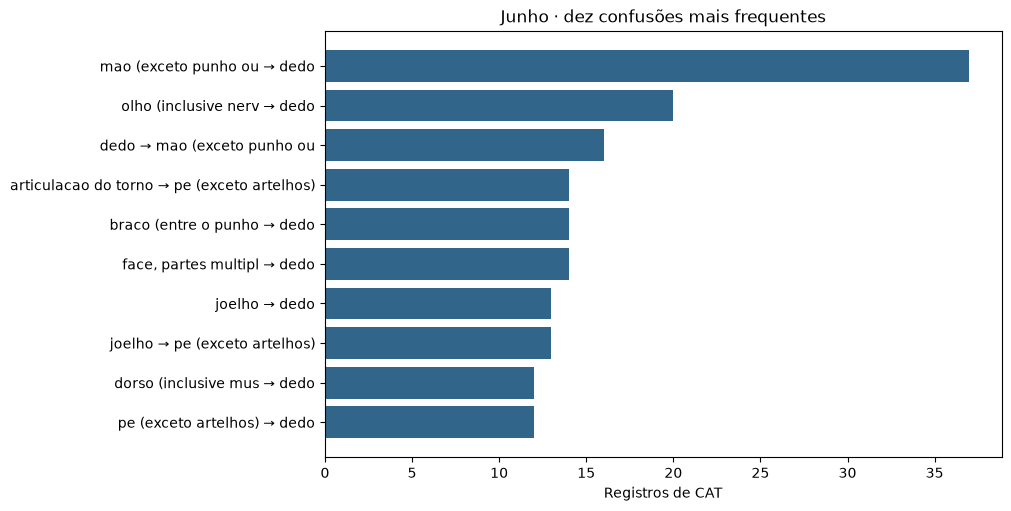

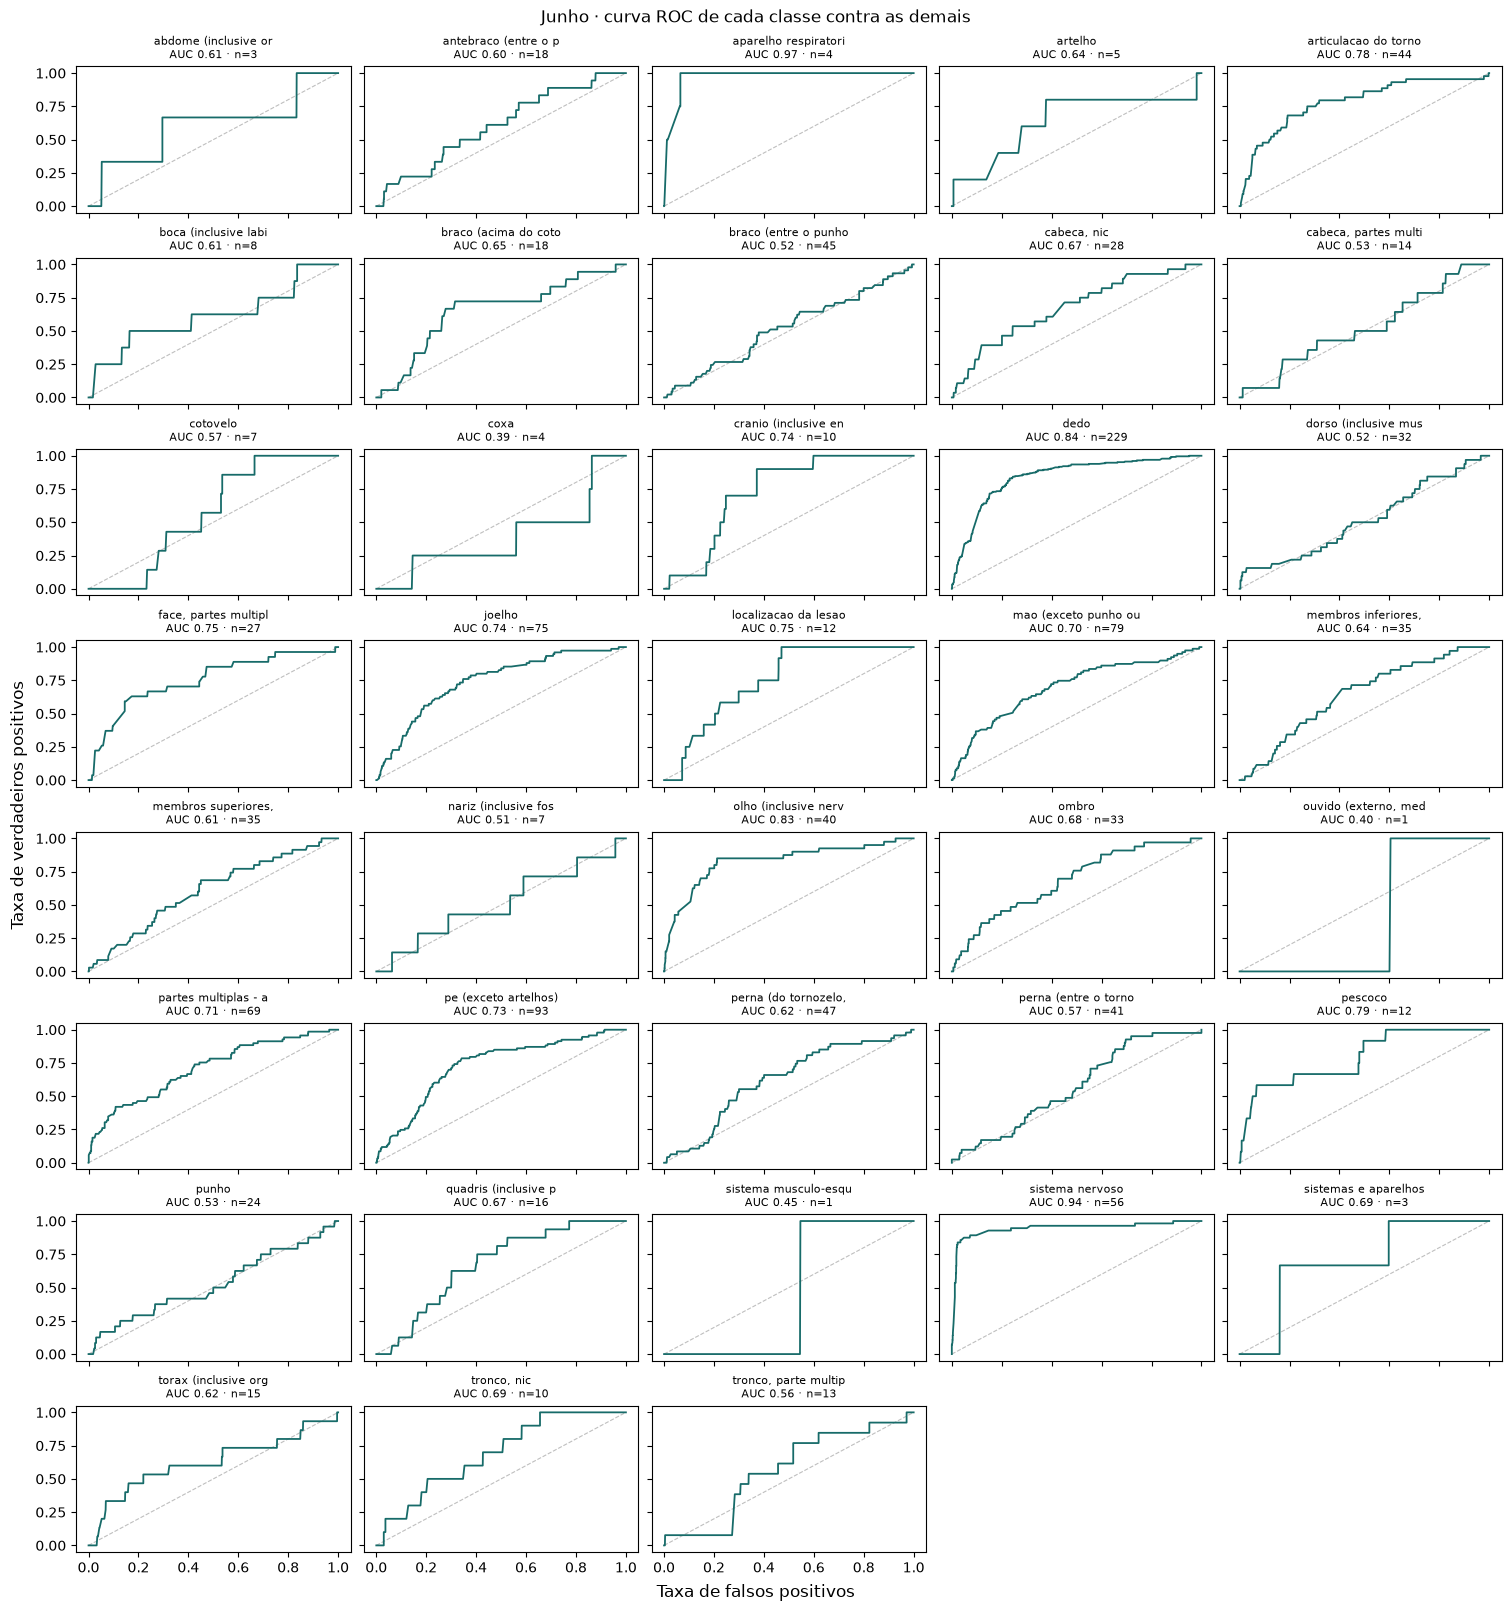

In [7]:
matriz_junho = matrizes[-1]
erros = matriz_junho.loc[matriz_junho.registrada.ne(matriz_junho.prevista) & matriz_junho.contagem.gt(0)]
erros = erros.sort_values(["contagem", "registrada", "prevista"], ascending=[False, True, True])
display(erros.head(10))
display(detalhe_junho.nlargest(1, "suporte")[["classe", "vp", "fp", "vn", "fn"]])
for nome, fig in [("confusoes_junho", confusoes(erros)),
                  ("roc_junho", painel_roc(pontos_roc[-1], tabelas_auc[-1]))]:
    fig.savefig(figuras / f"{nome}.png", dpi=135)
plt.show()